# Εργασία 2 – K-Nearest Neighbors & Χρονοσειρές

# Μέρος 1 – KNN

# Import Libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Load Dataset

In [ ]:
df = pd.read_csv('airline_passenger_satisfaction.csv')
df

,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0.0,4,...,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0.0,2,...,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1.0,3,...,3,4,4,5,4,3,3,3,3,Satisfied
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129875,129876,Male,28,Returning,Personal,Economy Plus,447,2,3.0,4,...,5,1,4,4,4,5,4,4,4,Neutral or Dissatisfied
129876,129877,Male,41,Returning,Personal,Economy Plus,308,0,0.0,5,...,5,2,5,2,2,4,3,2,5,Neutral or Dissatisfied
129877,129878,Male,42,Returning,Personal,Economy Plus,337,6,14.0,5,...,3,3,4,3,3,4,2,3,5,Neutral or Dissatisfied
129878,129879,Male,50,Returning,Personal,Economy Plus,337,31,22.0,4,...,4,4,5,3,3,4,5,3,5,Satisfied


In [ ]:
df.isna().sum()

ID                                          0
Gender                                      0
Age                                         0
Customer Type                               0
Type of Travel                              0
Class                                       0
Flight Distance                             0
Departure Delay                             0
Arrival Delay                             393
Departure and Arrival Time Convenience      0
Ease of Online Booking                      0
Check-in Service                            0
Online Boarding                             0
Gate Location                               0
On-board Service                            0
Seat Comfort                                0
Leg Room Service                            0
Cleanliness                                 0
Food and Drink                              0
In-flight Service                           0
In-flight Wifi Service                      0
In-flight Entertainment           

Το Arrival Delay έχει 393 κενές τιμές. Ο KNN δεν δουλεύει με κενές τιμές. Θα μπορούσα να σβήσω αυτές τις γραμμές ή να μην χρησιμοποιήσω τη στήλη. Επειδή είναι πολύ λίγες (0,3%), τις γέμισα με τη διάμεσο και κράτησα όλα τα δείγματα.

In [ ]:
df['Arrival Delay'] = df['Arrival Delay'].fillna(df['Arrival Delay'].median())
df = df.drop(columns=['ID'])

# Plot Variables

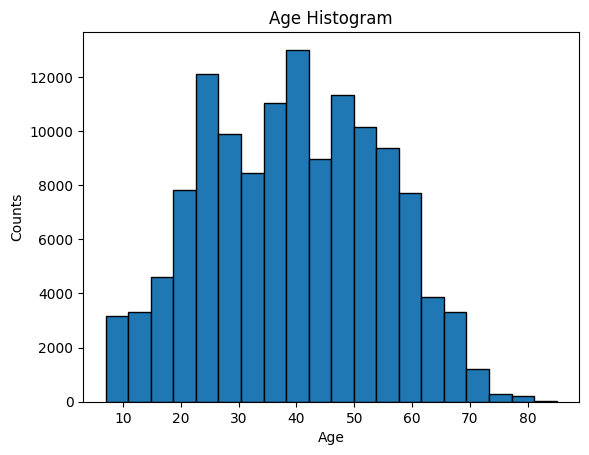

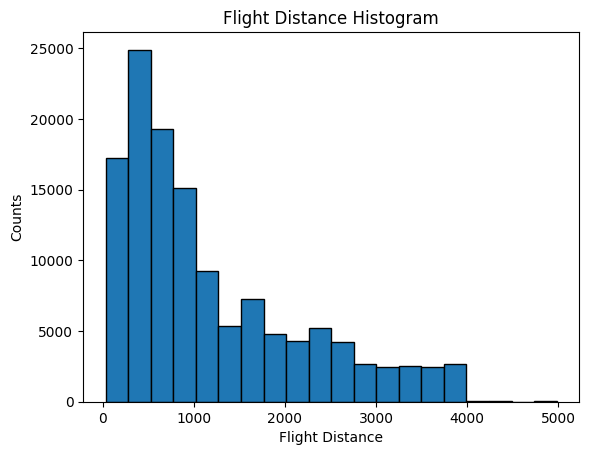

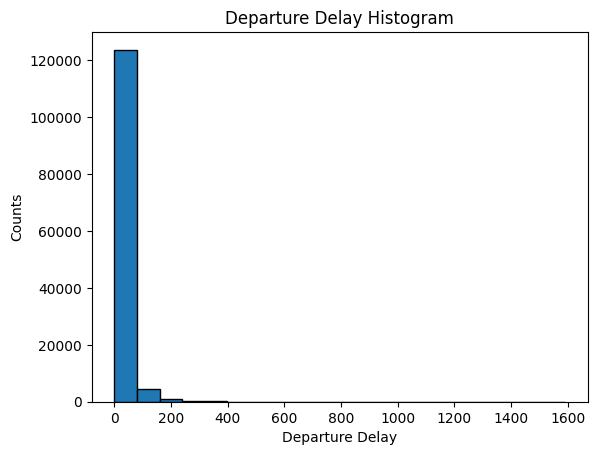

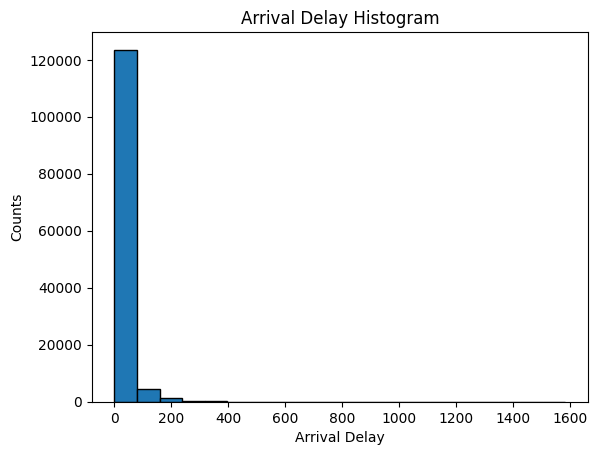

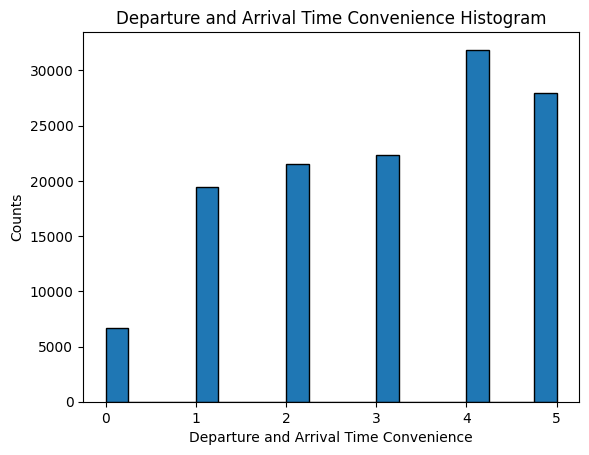

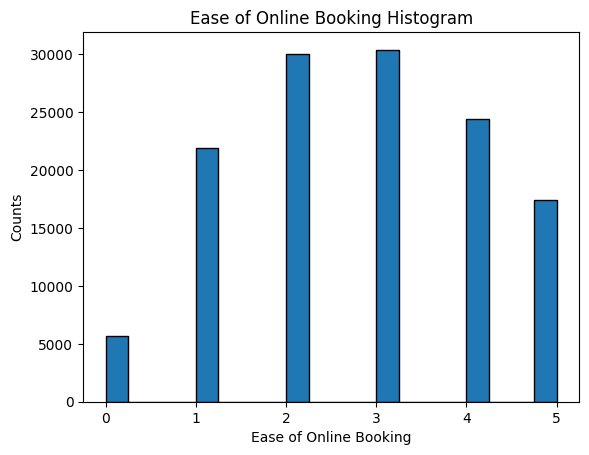

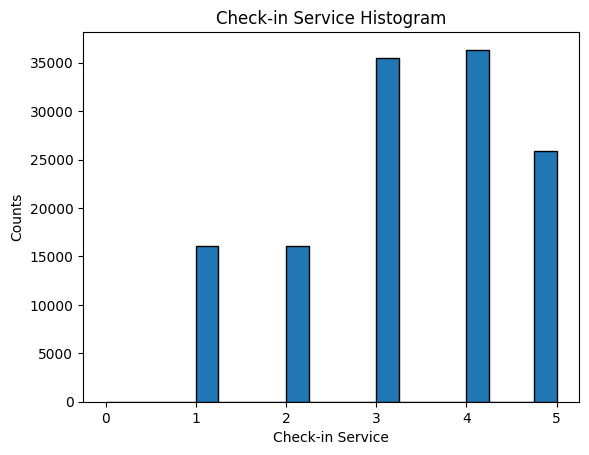

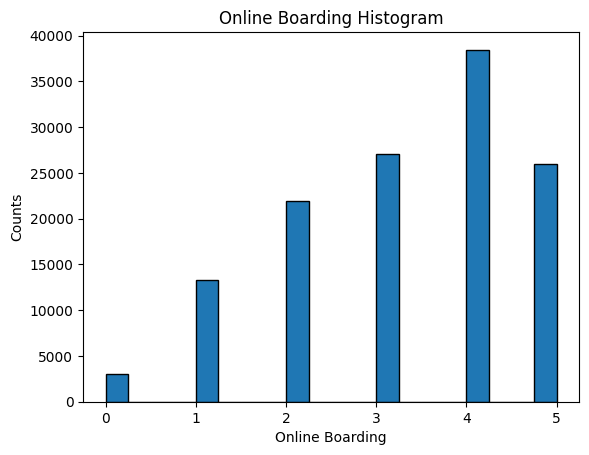

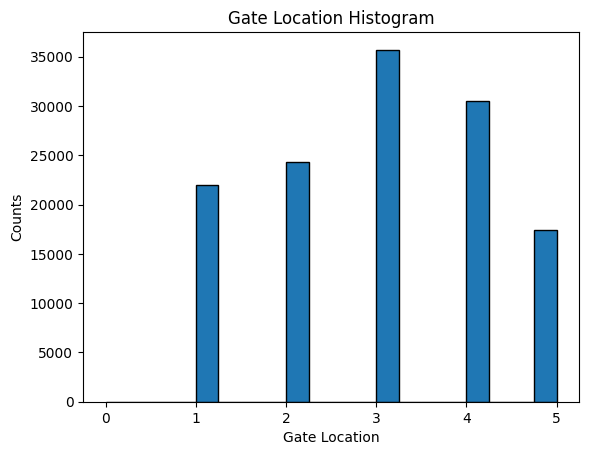

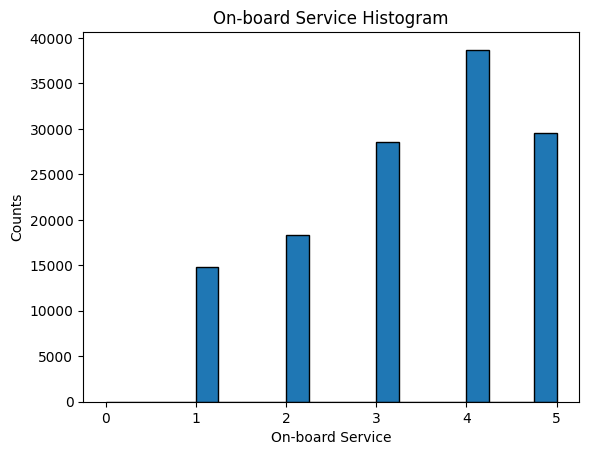

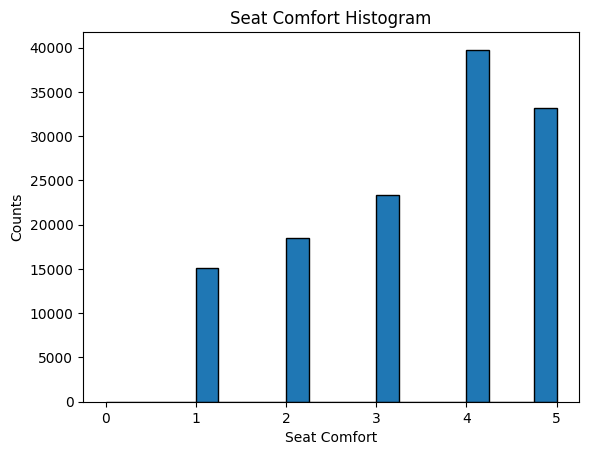

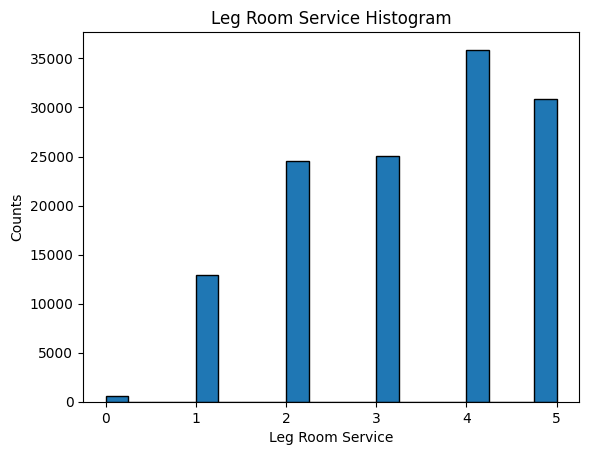

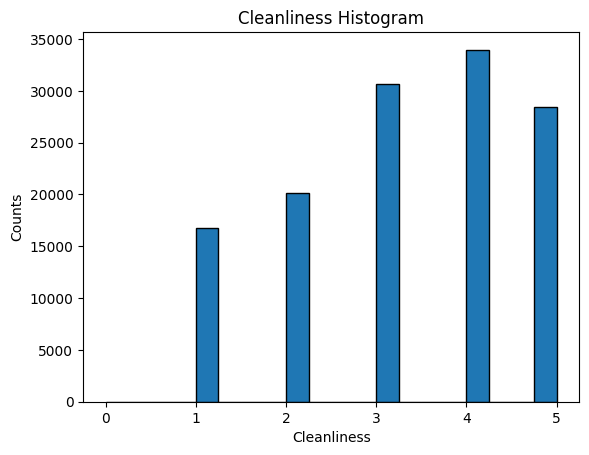

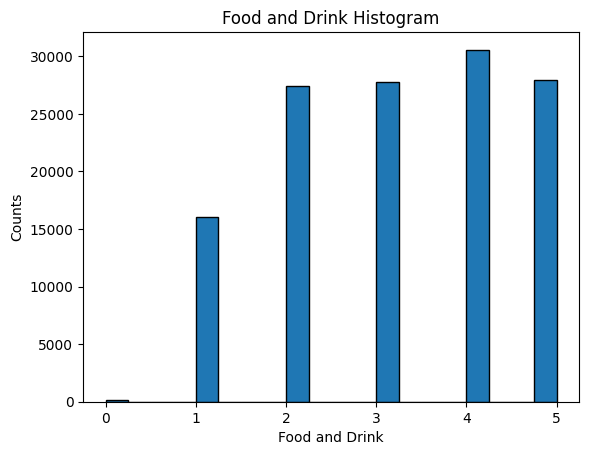

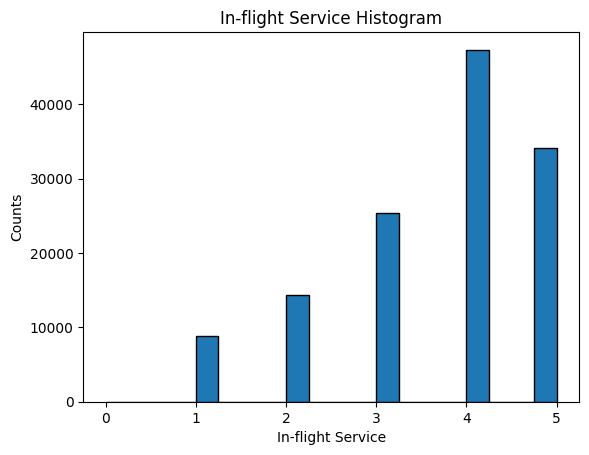

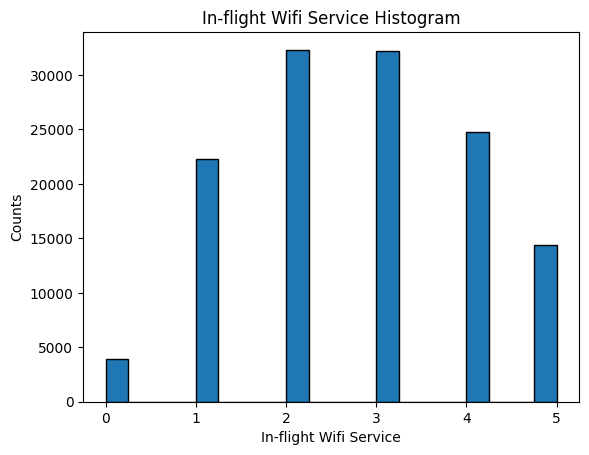

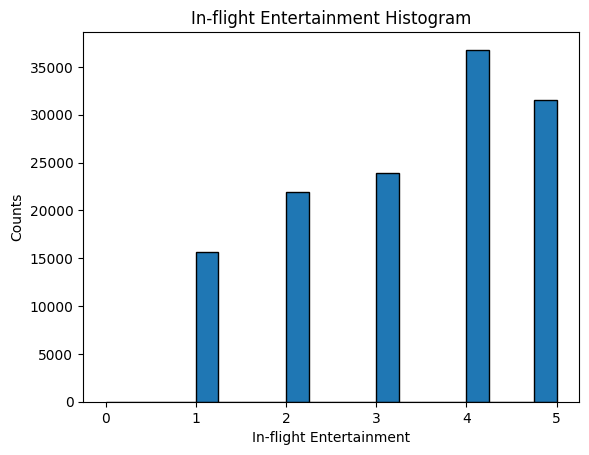

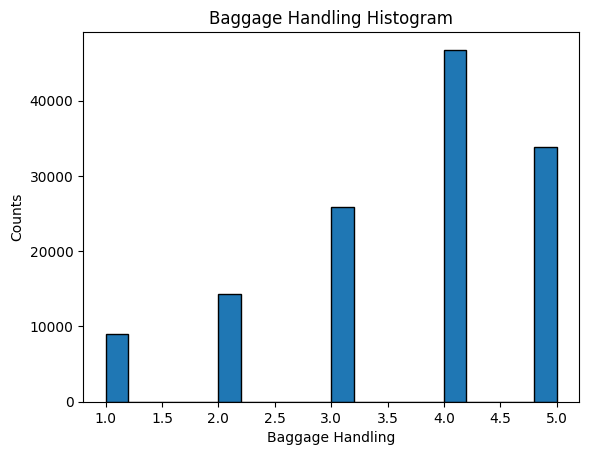

In [ ]:
num_cols = df.select_dtypes('number').columns
cat_cols = df.select_dtypes('object').columns

for col in num_cols:
    df[col].hist(bins=20, edgecolor='black')
    plt.title(col + ' Histogram')
    plt.xlabel(col)
    plt.ylabel('Counts')
    plt.grid(False)
    plt.show()

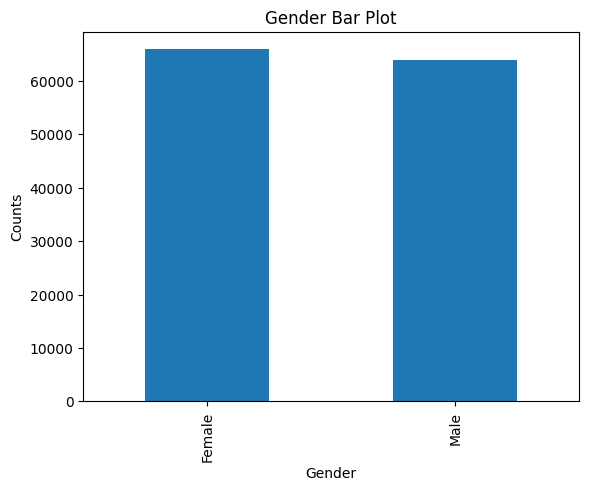

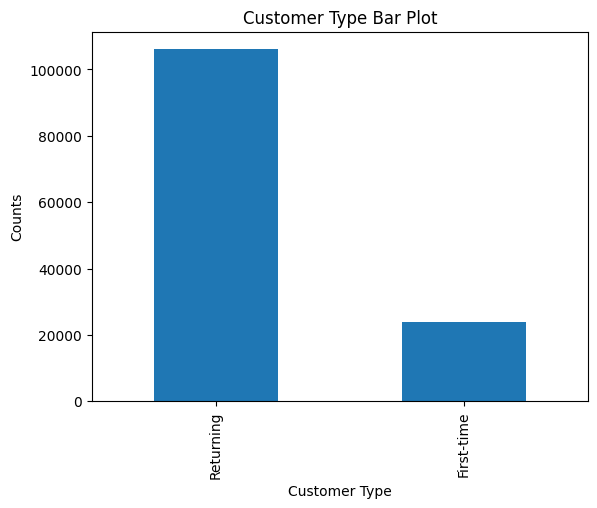

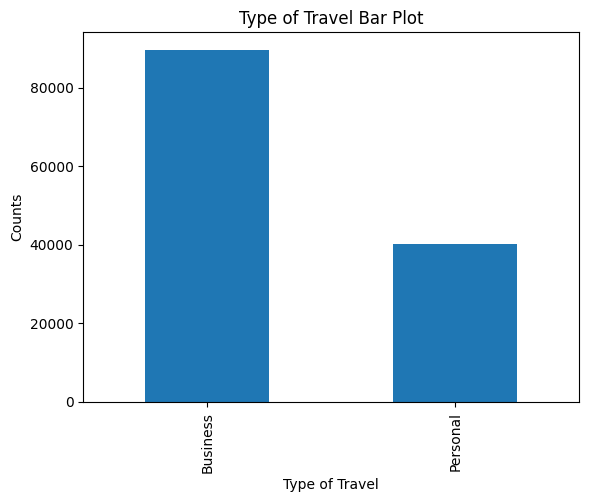

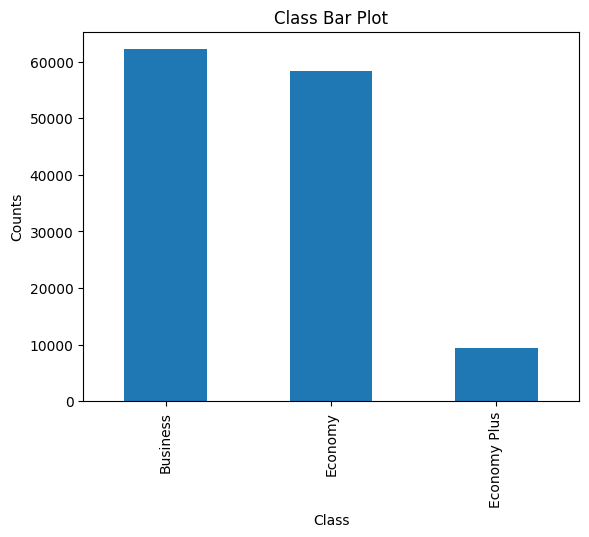

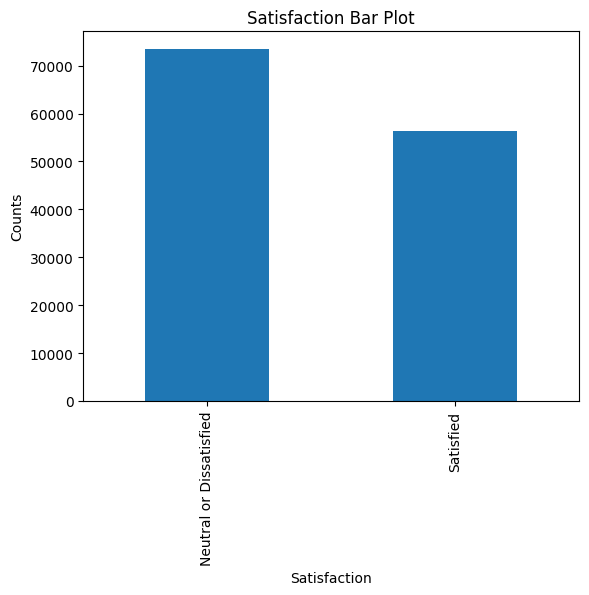

In [ ]:
for col in cat_cols:
    df[col].value_counts().plot(kind='bar')
    plt.title(col + ' Bar Plot')
    plt.xlabel(col)
    plt.ylabel('Counts')
    plt.show()

In [ ]:
df['Satisfaction'].value_counts(normalize=True)

Satisfaction
Neutral or Dissatisfied    0.565537
Satisfied                  0.434463
Name: proportion, dtype: float64

Ερώτηση: Υπερισχύει κάποια κλάση;

Απάντηση: Ναι, λίγο. Οι «Neutral or Dissatisfied» είναι το 56,6% και οι «Satisfied» το 43,4%. Η διαφορά δεν είναι μεγάλη, άρα οι κλάσεις είναι ελαφρώς μη ισορροπημένες και η ακρίβεια (accuracy) μπορεί να χρησιμοποιηθεί.

# Encoding

In [ ]:
df['Gender'] = df['Gender'].map({'Female': 0, 'Male': 1})
df['Customer Type'] = df['Customer Type'].map({'First-time': 0, 'Returning': 1})
df['Type of Travel'] = df['Type of Travel'].map({'Personal': 0, 'Business': 1})
df['Class'] = df['Class'].map({'Economy': 0, 'Economy Plus': 1, 'Business': 2})
df['Satisfaction'] = df['Satisfaction'].map({'Neutral or Dissatisfied': 0, 'Satisfied': 1})
df.head()

,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,Ease of Online Booking,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,48,0,1,2,821,2,5.0,3,3,...,3,5,2,5,5,5,3,5,5,0
1,0,35,1,1,2,821,26,39.0,2,2,...,5,4,5,5,3,5,2,5,5,1
2,1,41,1,1,2,853,0,0.0,4,4,...,3,5,3,5,5,3,4,3,3,1
3,1,50,1,1,2,1905,0,0.0,2,2,...,5,5,5,4,4,5,2,5,5,1
4,0,49,1,1,2,3470,0,1.0,3,3,...,3,4,4,5,4,3,3,3,3,1


Σχόλιο: Οι Gender, Customer Type, Type of Travel και Satisfaction έχουν δύο τιμές, οπότε τις έκανα 0/1 (label encoding). Το Class έχει σειρά (Economy < Economy Plus < Business), γι' αυτό το έκανα 0, 1, 2 (ordinal encoding). Θα μπορούσε να γίνει και one-hot, αλλά τότε θα είχαμε 3 νέες στήλες και θα χανόταν η σειρά. Τη στήλη ID την αφαίρεσα, γιατί είναι μόνο αναγνωριστικό.

# Convert DataFrame to Numpy arrays and Split

In [ ]:
input_df = df.drop(columns=['Satisfaction'])
targets_df = df['Satisfaction']

x = input_df.to_numpy()
y = targets_df.to_numpy()

seed = 0
test_size = 0.3
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)
print('Train samples:', x_train.shape[0])
print('Test samples:', x_test.shape[0])

Train samples: 90916
Test samples: 38964


# Normalization

In [ ]:
# θέσεις των αριθμητικών στηλών (όχι των κωδικοποιημένων κατηγορικών)
cat_names = ['Gender', 'Customer Type', 'Type of Travel', 'Class']
num_idx = [i for i, c in enumerate(input_df.columns) if c not in cat_names]

scaler = StandardScaler()
x_train[:, num_idx] = scaler.fit_transform(x_train[:, num_idx])
x_test[:, num_idx] = scaler.transform(x_test[:, num_idx])

Ερώτηση: Γιατί κανονικοποιούμε μόνο τις αριθμητικές;

Απάντηση: Ο KNN βασίζεται σε αποστάσεις. Μεταβλητές με μεγάλες τιμές, όπως το Flight Distance και τα Delays (έως χιλιάδες), θα κυριαρχούσαν στην απόσταση έναντι των βαθμολογιών 0-5. Με το StandardScaler όλες οι αριθμητικές έρχονται στην ίδια κλίμακα. Τις κατηγορικές δεν τις κανονικοποιούμε, γιατί είναι κωδικοί (0/1, 0/1/2) και όχι μετρήσεις.

# KNN

In [11]:
N = x_train.shape[0]
sqrt_n = int(np.sqrt(N))   # k = √N (στρογγυλοποιημένο προς τα κάτω)
print('N =', N, ', √N =', sqrt_n)

results = []
for k in [3, 5, 15, 51, 151, sqrt_n]:
    for w in ['uniform', 'distance']:
        knn = KNeighborsClassifier(n_neighbors=k, weights=w, metric='euclidean', n_jobs=-1)
        knn.fit(x_train, y_train)
        train_acc = knn.score(x_train, y_train) * 100
        test_acc = knn.score(x_test, y_test) * 100
        results.append([k, w, round(train_acc, 2), round(test_acc, 2)])

table = pd.DataFrame(results, columns=['k', 'weights', 'Train Accuracy', 'Test Accuracy'])
table

N = 90916 , √N = 301


,k,weights,Train Accuracy,Test Accuracy
0,3,uniform,95.91,92.38
1,3,distance,100.00,92.37
2,5,uniform,94.92,92.78
3,5,distance,100.00,92.79
4,15,uniform,93.44,92.71
5,15,distance,100.00,92.75
6,51,uniform,92.25,92.00
7,51,distance,100.00,92.09
8,151,uniform,91.21,91.05
9,151,distance,100.00,91.17


In [12]:
table.loc[table['Test Accuracy'].idxmax()]

k                        5
weights           distance
Train Accuracy       100.0
Test Accuracy        92.79
Name: 3, dtype: object

Ερώτηση: Ποιος είναι ο καλύτερος συνδυασμός;

Απάντηση: Ο καλύτερος συνδυασμός στο test είναι k=5 με weights=distance, με test accuracy 92.79% (το k=5 με uniform είναι σχεδόν ίδιο, 92.78%). Με weights=distance το train accuracy βγαίνει πάντα 100%, γιατί κάθε σημείο του train έχει τον εαυτό του ως γείτονα με απόσταση 0, γι' αυτό η σύγκριση γίνεται με το test. Όσο μεγαλώνει το k το test πέφτει (91.1% στο k=151 και 90.2-90.4% στο k=√N=301). Μικρό k σημαίνει υπερπροσαρμογή (train πολύ πάνω από test), ενώ πολύ μεγάλο k εξομαλύνει υπερβολικά το μοντέλο.

# Επιπλέον: k = N

Σημείωση: στην αρχή, κατά λάθος, δοκιμάσαμε k = N αντί για k = √N, επειδή το σύμβολο της ρίζας δεν φαινόταν στην εκφώνηση. Το k = N δεν ζητείται, αλλά δίνει χρήσιμη πληροφορία, γι' αυτό το αφήνουμε ως επιπλέον: δείχνει τι γίνεται όταν το k είναι το μεγαλύτερο δυνατό.

In [13]:
from sklearn.metrics import pairwise_distances

# Για k=N (N = πλήθος δειγμάτων του train, 90.916) δεν χρησιμοποιούμε την έτοιμη KNeighborsClassifier.
# Λόγος: με k=N η scikit-learn ταξινομεί και τους 90.916 γείτονες για κάθε δείγμα και φτιάχνει
# πίνακα 90.916 x 90.916, που ζητά πάνω από 60 GB μνήμης και δεν ολοκληρώνεται σε εύλογο χρόνο.
# Με k=N όμως ψηφίζουν ούτως ή άλλως όλα τα δείγματα, άρα δεν χρειάζεται καθόλου να βρούμε
# "τους κοντινότερους". Υπολογίζουμε τις ευκλείδειες αποστάσεις (σε κομμάτια των 500 δειγμάτων)
# και παίρνουμε κατευθείαν την ψήφο όλων των γειτόνων:
#   - uniform: όλοι οι γείτονες έχουν βάρος 1, άρα προβλέπεται πάντα η πλειοψηφούσα κλάση
#   - distance: βάρος 1/απόσταση, δηλαδή οι κοντινοί γείτονες μετράνε περισσότερο
# Το αποτέλεσμα είναι το ίδιο με της KNeighborsClassifier, απλώς πιο γρήγορο και με λιγότερη μνήμη.
def knn_all(x, w):
    if w == 'uniform':
        # όλοι οι γείτονες με ίδιο βάρος: προβλέπεται πάντα η πλειοψηφούσα κλάση του train
        return np.full(len(x), y_train.mean() > 0.5)
    pred = []
    for i in range(0, len(x), 500):
        d = pairwise_distances(x[i:i+500], x_train)
        weights = 1 / np.maximum(d, 1e-9)
        pred.append(weights @ y_train / weights.sum(axis=1) > 0.5)
    return np.concatenate(pred)

results_n = []
for w in ['uniform', 'distance']:
    pred_train, pred_test = knn_all(x_train, w), knn_all(x_test, w)
    results_n.append([N, w, round(np.mean(pred_train == y_train) * 100, 2), round(np.mean(pred_test == y_test) * 100, 2)])

pd.DataFrame(results_n, columns=['k', 'weights', 'Train Accuracy', 'Test Accuracy'])

,k,weights,Train Accuracy,Test Accuracy
0,90916,uniform,56.63,56.38
1,90916,distance,100.00,65.29


Σχόλιο: Με k=N (όλο το train) το uniform δίνει test accuracy 56.4%, δηλαδή προβλέπει πάντα την πλειοψηφούσα κλάση («Neutral or Dissatisfied», που είναι το 56.6% των δεδομένων), και το distance 65.3%. Είναι το άκρο της υποπροσαρμογής: όσο μεγαλώνει το k, το μοντέλο πλησιάζει την απλή πρόβλεψη της πλειοψηφίας.

# Μέρος 2 – Πρόβλεψη Χρονοσειρών

# Import Libraries

In [ ]:
!pip install holidays -q

In [ ]:
import yfinance as yf
import plotly.graph_objects as go
import holidays
from statsmodels.tsa.stattools import adfuller, kpss, grangercausalitytests
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Load Dataset

In [ ]:
df = yf.Ticker('DX-Y.NYB').history(period='5y')
df = df.drop(columns=['Volume', 'Dividends', 'Stock Splits'])
df.index = df.index.tz_localize(None)
df

,Open,High,Low,Close
Date,,,,
2021-10-22,93.750000,93.790001,93.540001,93.610001
2021-10-25,93.660004,93.959999,93.480003,93.809998
2021-10-26,93.839996,94.019997,93.709999,93.949997
2021-10-27,93.970001,94.010002,93.690002,93.860001
2021-10-28,93.879997,93.970001,93.279999,93.349998
...,...,...,...,...
2026-10-16,102.040001,102.089996,101.580002,101.839996
2026-10-19,102.010002,102.080002,101.769997,101.980003
2026-10-20,101.980003,101.980003,101.510002,101.730003


In [ ]:
df.describe()

,Open,High,Low,Close
count,1257.000000,1257.000000,1257.000000,1257.000000
mean,102.228455,102.561188,101.906178,102.240746
std,3.841564,3.895323,3.775622,3.838594
min,93.360001,93.790001,93.279999,93.349998
25%,99.099998,99.389999,98.839996,99.129997
50%,102.300003,102.629997,101.980003,102.300003
75%,104.620003,105.010002,104.260002,104.669998
max,114.190002,114.779999,113.330002,114.110001


Ερώτηση: Τι σημαίνουν οι μεταβλητές OHLC και τι δείχνουν η μέση τιμή και η τυπική απόκλιση;

Απάντηση: Open: η τιμή ανοίγματος της ημέρας, High: η υψηλότερη τιμή της ημέρας, Low: η χαμηλότερη τιμή της ημέρας, Close: η τιμή κλεισίματος (Volume είναι ο όγκος συναλλαγών, τον αφαίρεσα). Χρησιμοποίησα τον δείκτη δολαρίου (DX-Y.NYB). Η μέση τιμή είναι περίπου 102.2 και η τυπική απόκλιση περίπου 3.8 για όλες τις στήλες, δηλαδή η τιμή κινήθηκε γύρω στο 102 με διακύμανση περίπου ±4 μονάδες (από 93.3 έως 114.8) στα 5 έτη.

# Plot Time Series

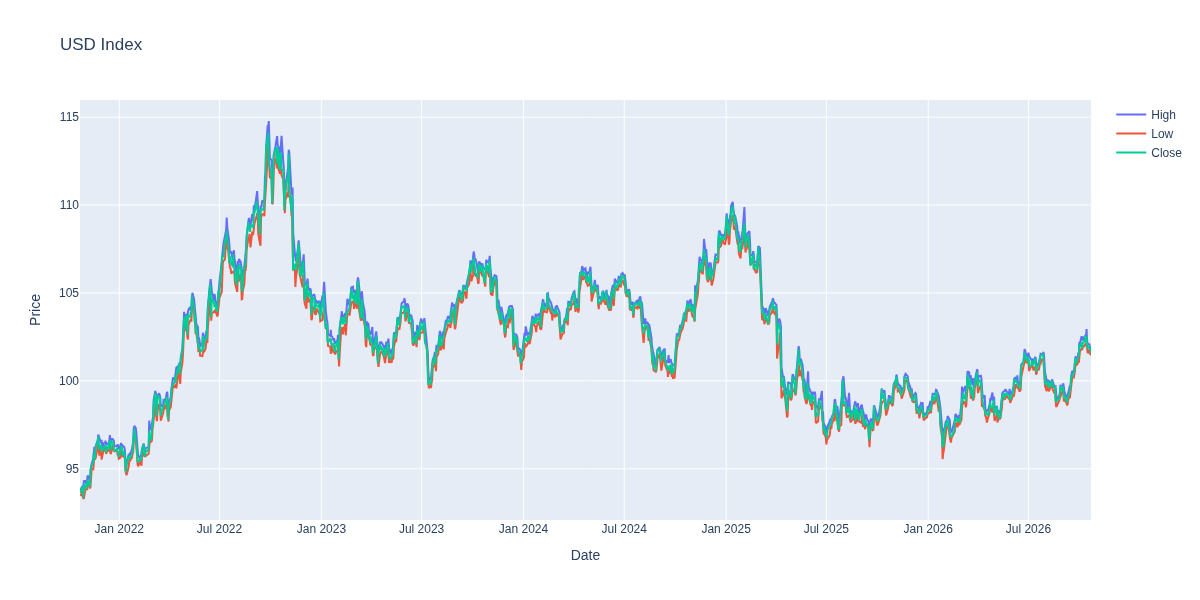

In [ ]:
fig = go.Figure()
for col in ['High', 'Low', 'Close']:
    fig.add_trace(go.Scatter(x=df.index, y=df[col], mode='lines', name=col))
fig.update_layout(title='USD Index', xaxis_title='Date', yaxis_title='Price', width=1200, height=600)
fig.show()

Ερώτηση: Είναι οι χρονοσειρές στάσιμες;

Απάντηση: Δεν φαίνονται στάσιμες. Οι τιμές δεν κινούνται γύρω από έναν σταθερό μέσο όρο: ανεβαίνουν και πέφτουν για μεγάλα διαστήματα (τάση), άρα ο μέσος όρος αλλάζει με τον χρόνο. Οι High, Low και Close κινούνται σχεδόν ίδια.

# ADF and KPSS Tests

In [ ]:
for col in ['High', 'Low', 'Close']:
    adf_p = adfuller(df[col])[1]
    kpss_p = kpss(df[col], nlags='auto')[1]
    print(col, '| ADF p-value:', round(adf_p, 4), '| KPSS p-value:', round(kpss_p, 4))

High | ADF p-value: 0.0802 | KPSS p-value: 0.01
Low | ADF p-value: 0.0902 | KPSS p-value: 0.01
Close | ADF p-value: 0.0973 | KPSS p-value: 0.01


Ερώτηση: Τι δείχνουν τα τεστ;

Απάντηση: Χρησιμοποίησα τις adfuller και kpss της statsmodels, γιατί στην scipy δεν βρέθηκαν αυτά τα τεστ. ADF: p-value περίπου 0.08-0.10 για τις τρεις σειρές, δηλαδή μεγαλύτερο από 0.05, άρα δεν απορρίπτεται η μηδενική υπόθεση (μη στάσιμη σειρά). KPSS: p-value 0.01, μικρότερο από 0.05, άρα απορρίπτεται η υπόθεση ότι η σειρά είναι στάσιμη. Και τα δύο τεστ λένε ότι οι σειρές είναι μη στάσιμες, όπως φάνηκε και στο γράφημα (το ADF είναι οριακό, το KPSS είναι σαφές).

# Split Train-Test and Timeframes

In [ ]:
def make(F, H, K=None):
    idx = np.arange(H, len(F))
    X = np.array([F[i-H:i].ravel() for i in idx])
    if K is not None:
        X = np.hstack([X, K[idx]])
    return X, idx

def evaluate(F, price, H, K=None, returns=False):
    X, idx = make(F, H, K)
    y = F[idx, 3] if returns else price[idx]
    split = int(0.7 * len(X))
    model = LinearRegression().fit(X[:split], y[:split])
    pred = model.predict(X)
    if returns:
        pred = price[idx - 1] * np.exp(pred)
    actual = price[idx]
    train_mae = mean_absolute_error(actual[:split], pred[:split])
    test_mae = mean_absolute_error(actual[split:], pred[split:])
    return train_mae, test_mae, pred, actual, idx, split

price = df['Close'].to_numpy()
F = df[['Open', 'High', 'Low', 'Close']].to_numpy()
Hs = [1, 5, 15, 30]

# Linear Regression: Close(t+1)

    Train MAE  Test MAE
H                      
1       0.370     0.287
5       0.367     0.292
15      0.360     0.296
30      0.353     0.317


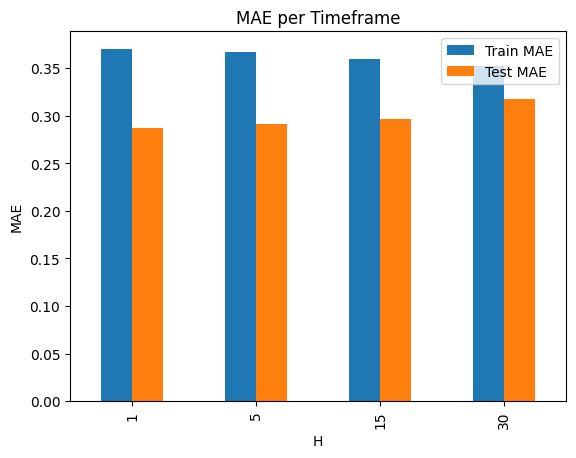

In [ ]:
res = []
for H in Hs:
    tr, te = evaluate(F, price, H)[:2]
    res.append([H, tr, te])
res = pd.DataFrame(res, columns=['H', 'Train MAE', 'Test MAE']).set_index('H')
print(res.round(3))

res.plot(kind='bar')
plt.title('MAE per Timeframe')
plt.xlabel('H')
plt.ylabel('MAE')
plt.show()

Σχόλιο: Το test MAE είναι περίπου 0.29-0.32, δηλαδή το μοντέλο αστοχεί κατά μέσο όρο 0.3 μονάδες σε τιμές γύρω στο 102. Το καλύτερο είναι το H=1 (0.287) και όσο μεγαλώνει το H το test χειροτερεύει λίγο (0.317 για H=30), ενώ το train βελτιώνεται (0.370 → 0.353). Οι παλιότερες μέρες δεν προσθέτουν πολλή πληροφορία και το μοντέλο προσαρμόζεται περισσότερο στο train. Το test MAE είναι μικρότερο από το train MAE, πιθανόν επειδή η περίοδος του test ήταν πιο ήρεμη.

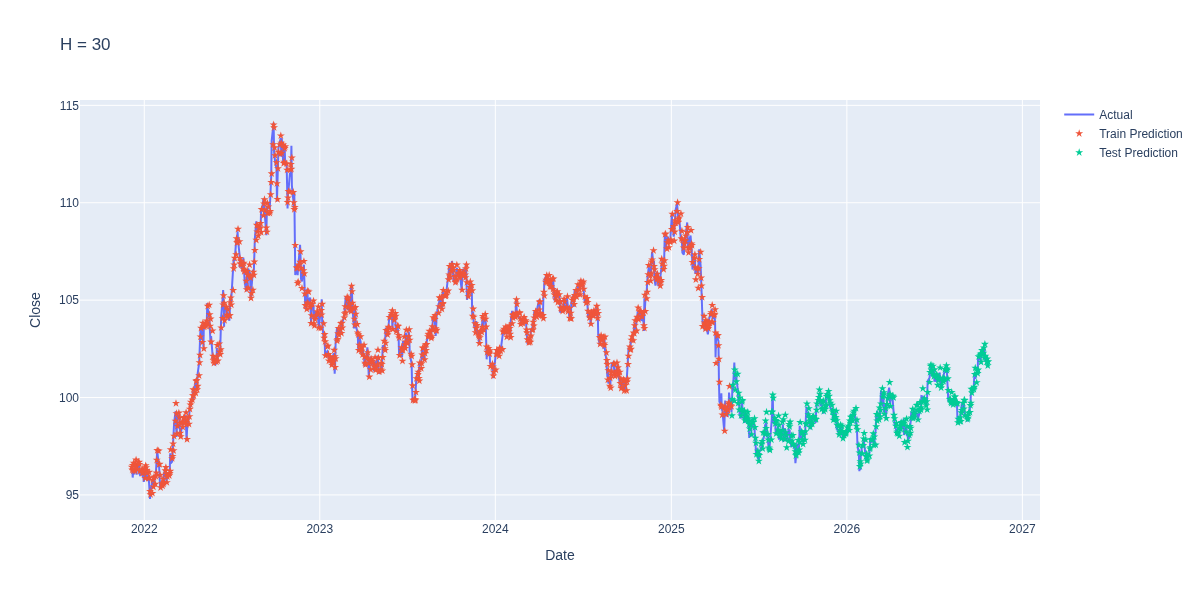

In [ ]:
_, _, pred, actual, idx, split = evaluate(F, price, 30)

fig = go.Figure()
fig.add_trace(go.Scatter(x=df.index[idx], y=actual, mode='lines', name='Actual'))
fig.add_trace(go.Scatter(x=df.index[idx][:split], y=pred[:split], mode='markers', marker_symbol='star', name='Train Prediction'))
fig.add_trace(go.Scatter(x=df.index[idx][split:], y=pred[split:], mode='markers', marker_symbol='star', name='Test Prediction'))
fig.update_layout(title='H = 30', xaxis_title='Date', yaxis_title='Close', width=1200, height=600)
fig.show()

# Log-Returns

    Train MAE  Test MAE
H                      
1       0.370     0.292
5       0.368     0.292
15      0.362     0.298
30      0.354     0.314


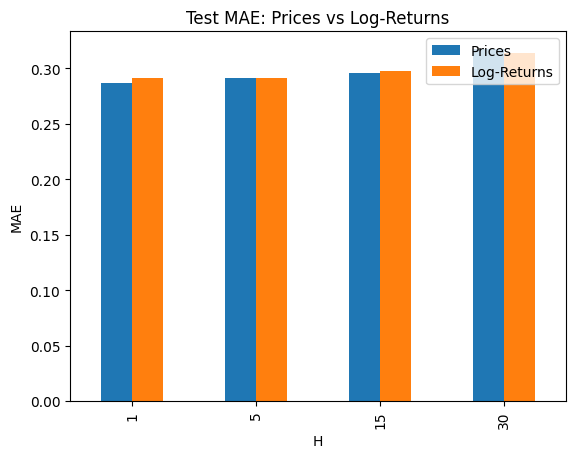

In [ ]:
logret = np.log(df[['Open', 'High', 'Low', 'Close']]).diff().dropna()
F_ret = logret.to_numpy()
price_ret = df['Close'].to_numpy()[1:]

res_ret = []
for H in Hs:
    tr, te = evaluate(F_ret, price_ret, H, returns=True)[:2]
    res_ret.append([H, tr, te])
res_ret = pd.DataFrame(res_ret, columns=['H', 'Train MAE', 'Test MAE']).set_index('H')
print(res_ret.round(3))

pd.concat([res['Test MAE'], res_ret['Test MAE']], axis=1, keys=['Prices', 'Log-Returns']).plot(kind='bar')
plt.title('Test MAE: Prices vs Log-Returns')
plt.xlabel('H')
plt.ylabel('MAE')
plt.show()

Ερώτηση: Πώς συγκρίνονται τα δύο μοντέλα;

Απάντηση: Με log-returns, το test MAE σε απόλυτες τιμές είναι σχεδόν το ίδιο με πριν: 0.292, 0.292, 0.298, 0.314 για H=1, 5, 15, 30, ενώ στις αρχικές τιμές ήταν 0.287, 0.292, 0.296, 0.317. Δεν υπάρχει ουσιαστική διαφορά. Ο μετασχηματισμός κάνει τα δεδομένα στάσιμα, αλλά η πρόβλεψη δεν βελτιώθηκε.

# Granger Causality

In [ ]:
for col in ['High', 'Low']:
    out = grangercausalitytests(logret[['Close', col]], maxlag=5, verbose=False)
    print(col, '->', 'Close, p-values per lag:', [round(float(out[l][0]['ssr_ftest'][1]), 4) for l in range(1, 6)])

High -> Close, p-values per lag: [0.2112, 0.6587, 0.2934, 0.4562, 0.1319]
Low -> Close, p-values per lag: [0.3076, 0.6769, 0.8507, 0.8365, 0.8936]


Ερώτηση: Είναι χρήσιμες οι High, Low για την πρόβλεψη του Close;

Απάντηση: Για τα High → Close και Low → Close όλα τα p-values για lag 1 έως 5 είναι πάνω από 0.05 (από 0.13 έως 0.89). Άρα δεν απορρίπτεται η μηδενική υπόθεση και τα High, Low δεν βοηθούν στατιστικά σημαντικά στην πρόβλεψη του Close. Το τεστ έγινε στα log-returns, γιατί το Granger test θέλει στάσιμες σειρές.

# Extra Features

    Train MAE  Test MAE
H                      
1       0.371     0.288
5       0.362     0.291
15      0.351     0.312
30      0.339     0.375


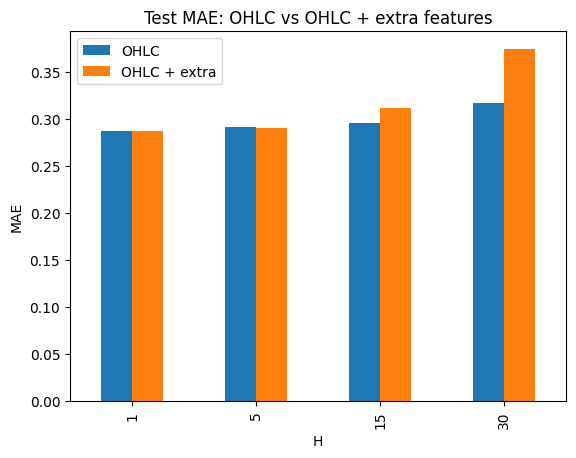

In [ ]:
sp = yf.Ticker('^GSPC').history(period='5y')['Close']
sp.index = sp.index.tz_localize(None)
df['SP500'] = sp.reindex(df.index).ffill()
df = df.dropna()

us_holidays = holidays.US()
df['Weekday'] = df.index.weekday
df['Month'] = df.index.month
df['Holiday'] = [int(d in us_holidays) for d in df.index]

price = df['Close'].to_numpy()
F2 = df[['Open', 'High', 'Low', 'Close', 'SP500']].to_numpy()
K = df[['Weekday', 'Month', 'Holiday']].to_numpy()   # γνωστά μελλοντικά χαρακτηριστικά της ημέρας t+1

res2 = []
for H in Hs:
    tr, te = evaluate(F2, price, H, K)[:2]
    res2.append([H, tr, te])
res2 = pd.DataFrame(res2, columns=['H', 'Train MAE', 'Test MAE']).set_index('H')
print(res2.round(3))

pd.concat([res['Test MAE'], res2['Test MAE']], axis=1, keys=['OHLC', 'OHLC + extra']).plot(kind='bar')
plt.title('Test MAE: OHLC vs OHLC + extra features')
plt.xlabel('H')
plt.ylabel('MAE')
plt.show()

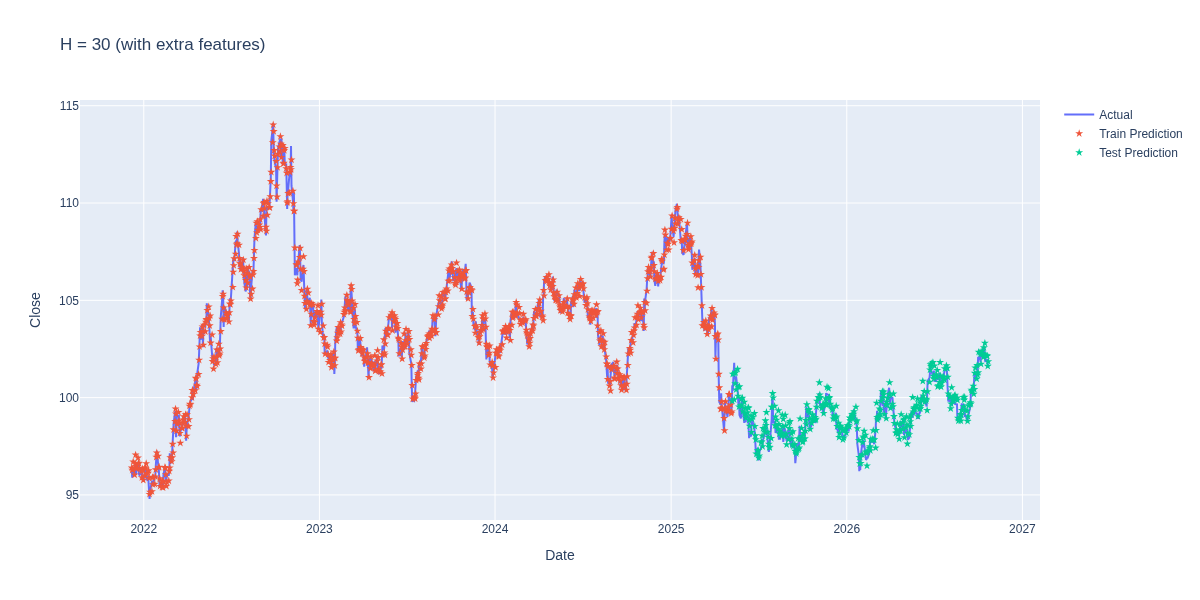

In [ ]:
_, _, pred, actual, idx, split = evaluate(F2, price, 30, K)

fig = go.Figure()
fig.add_trace(go.Scatter(x=df.index[idx], y=actual, mode='lines', name='Actual'))
fig.add_trace(go.Scatter(x=df.index[idx][:split], y=pred[:split], mode='markers', marker_symbol='star', name='Train Prediction'))
fig.add_trace(go.Scatter(x=df.index[idx][split:], y=pred[split:], mode='markers', marker_symbol='star', name='Test Prediction'))
fig.update_layout(title='H = 30 (with extra features)', xaxis_title='Date', yaxis_title='Close', width=1200, height=600)
fig.show()

Σχόλιο: Για H=1 και H=5 σχεδόν καμία διαφορά (test MAE 0.288 και 0.291), ενώ για H=15 και H=30 το test χειροτερεύει (0.312 και 0.375) και το train βελτιώνεται (0.339 για H=30). Άρα τα επιπλέον χαρακτηριστικά (S&P500, ημέρα, μήνας, αργίες) δεν βελτίωσαν το μοντέλο. Με πολλά χαρακτηριστικά το μοντέλο υπερπροσαρμόζεται στο train.